<a href="https://colab.research.google.com/github/mariettarosemathew-ui/Case_Study_Preprocessing/blob/main/Case_Study_Starter_Notebook_Airbnb_NYC_Preprocessing_Marietta.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Case Study Assessment — NYC Airbnb Data Preprocessing
### Student Name:
### Date:

This notebook is your submission template. Fill in each section — do not delete the headers. Use markdown cells for your written justifications, right next to the code that supports them.

In [1]:
import pandas as pd
url = "https://raw.githubusercontent.com/erkansirin78/datasets/master/AB_NYC_2019.csv"
df = pd.read_csv(url)
df.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


---
## Part 1 — Data Understanding & Quality Audit

In [2]:
# TODO: shape, dtypes, missing value summary
print(df.shape)
print(df.dtypes)
print(df.isna().sum())

(48895, 16)
id                                  int64
name                               object
host_id                             int64
host_name                          object
neighbourhood_group                object
neighbourhood                      object
latitude                          float64
longitude                         float64
room_type                          object
price                               int64
minimum_nights                      int64
number_of_reviews                   int64
last_review                        object
reviews_per_month                 float64
calculated_host_listings_count      int64
availability_365                    int64
dtype: object
id                                    0
name                                 16
host_id                               0
host_name                            21
neighbourhood_group                   0
neighbourhood                         0
latitude                              0
longitude             

In [3]:
# TODO: check for values that are technically present but don't make real-world sense
print("Price less than or equal to zero :")
print(df[df["price"]<=0].shape[0])

print("Minimum nights less than 1 :")
print(df[df["minimum_nights"]<1].shape[0])

print("Avilability outside 0 to 365 :")
print(df[(df["availability_365"]<0)|(df["availability_365"]>365)].shape[0])


Price less than or equal to zero :
11
Minimum nights less than 1 :
0
Avilability outside 0 to 365 :
0


In [4]:
# TODO: duplicate check
df.duplicated().sum()

np.int64(0)

**Written notes — what did you find, and what looks suspicious?**

The NYC Airbnb dataset contains information about Airbnb listings, including their prices, room types, locations, hosts, and reviews.

I checked the dataset's shape, data types, missing values, suspicious values, and duplicate records.

Some values that need investigation include prices that are zero or negative, minimum-night requirements below 1, and availability values outside the range of 0 to 365 days. Missing values in columns such as name, host_name, last_review, and reviews_per_month also require attention.

The dataset may contain duplicate records, so checking for duplicates is important. Unusual values should be investigated before removing them because some may represent genuine listings rather than errors.

---
## Part 2 — Missing Value Diagnosis & Treatment

In [5]:
# TODO: investigate missingness pattern(s) across columns
print("Missing values in each column :")
print(df.isna().sum())

print("Percentage of missing values in each column :")
print((df.isna().mean()*100).round(2))

Missing values in each column :
id                                    0
name                                 16
host_id                               0
host_name                            21
neighbourhood_group                   0
neighbourhood                         0
latitude                              0
longitude                             0
room_type                             0
price                                 0
minimum_nights                        0
number_of_reviews                     0
last_review                       10052
reviews_per_month                 10052
calculated_host_listings_count        0
availability_365                      0
dtype: int64
Percentage of missing values in each column :
id                                 0.00
name                               0.03
host_id                            0.00
host_name                          0.04
neighbourhood_group                0.00
neighbourhood                      0.00
latitude                     

**Written justification — MCAR / MAR / MNAR classification per column, and your reasoning:**

The missing values in the Airbnb dataset may have different reasons:

* name: The listing name is missing. The reason cannot be determined from the missing value alone, so it is difficult to classify confidently as MCAR, MAR, or MNAR.
* host_name: The host's name is missing. The reason is not known from the dataset alone, so its missingness mechanism cannot be confirmed.
* last_review: This may be missing because a listing has not received a review. Therefore, the missingness may be related to the listing's review history rather than being completely random.
* reviews_per_month: This may be missing for listings without reviews. Its missingness may be related to review activity.

The missingness mechanisms cannot be determined with certainty from the missing-value counts alone. More information about why the values are missing would be needed to classify each column confidently as MCAR, MAR, or MNAR.

In [6]:
# TODO: apply your chosen treatment(s)
df["name"]=df["name"].fillna("Unknown")
df["host_name"]=df["host_name"].fillna("Unknown")
df["reviews_per_month"]=df["reviews_per_month"].fillna(0)
df["last_review"] = df["last_review"].fillna("No Review")

df.isna().sum()

,0
id,0
name,0
host_id,0
host_name,0
neighbourhood_group,0
neighbourhood,0
latitude,0
longitude,0
room_type,0
price,0


**Written justification — why this treatment for each column, and what you'd risk with `dropna()` instead:**

I used different treatments depending on the meaning of each column.

* name: Missing values were replaced with "Unknown" so that listings would not be lost just because their names were unavailable.
* host_name: Missing values were replaced with "Unknown" to preserve the listing records.
* reviews_per_month: Missing values were replaced with 0 to represent no monthly reviews, where the missingness indicates that the listing has no reviews. This assumption should be checked because a missing value does not always mean zero.
* last_review: Missing values were represented as "No Review" to indicate that a review date was unavailable, rather than inventing a date.

Using dropna() would remove every row containing a missing value in the selected columns. This could discard many valid listings and reduce the amount of data available for analysis. However, filling missing values also requires care because an assumed value may not represent the true situation.

---
## Part 3 — Outlier Detection & Treatment

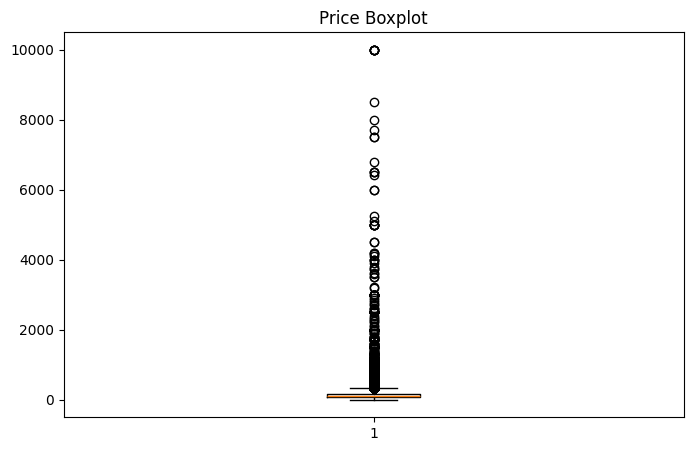

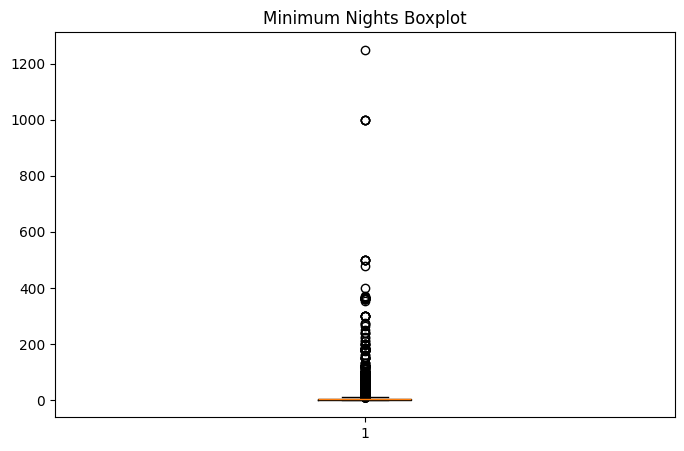

Price lower limit: -90.0
Price upper limit: 334.0
Price outliers: 2972
Minimum nights lower limit: -5.0
Minimum nights upper limit: 11.0
Minimum nights outliers: 6607


In [7]:
# TODO: detect outliers in at least two numeric columns
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.boxplot(df['price'])
plt.title('Price Boxplot')

plt.figure(figsize=(8,5))
plt.boxplot(df['minimum_nights'])
plt.title('Minimum Nights Boxplot')
plt.show()

# Detect outliers in price using IQR
Q1 = df["price"].quantile(0.25)
Q3 = df["price"].quantile(0.75)
IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

price_outliers = df[
    (df["price"] < lower_limit) |
    (df["price"] > upper_limit)
]
print("Price lower limit:", lower_limit)
print("Price upper limit:", upper_limit)
print("Price outliers:", len(price_outliers))


# Detect outliers in minimum nights using IQR
Q1 = df["minimum_nights"].quantile(0.25)
Q3 = df["minimum_nights"].quantile(0.75)
IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

nights_outliers = df[
    (df["minimum_nights"] < lower_limit) |
    (df["minimum_nights"] > upper_limit)
]

print("Minimum nights lower limit:", lower_limit)
print("Minimum nights upper limit:", upper_limit)
print("Minimum nights outliers:", len(nights_outliers))


written justification _ for each outlier group ,is it an error or a genuene listing?what evedance support your call?

The IQR method was used to identify potential outliers in the price and minimum_nights columns. The box plots helped visualise the distributions, while the IQR limits identified unusually low or high values.

Not all outliers are errors. High prices and long minimum-night requirements may represent genuine Airbnb listings. Therefore, I would not remove all IQR outliers automatically. Values that appear invalid should be investigated, while plausible values should be retained to avoid losing useful information.

In [11]:
# TODO: apply treatment consistent with your judgment above

# Remove listings with invalid prices
df = df[df["price"] > 0].copy()

# Limit minimum nights to 3 years
df["minimum_nights"] = df["minimum_nights"].clip(upper=1095)

# Check the data after treatment
print("Rows after treatment:", df.shape[0])
print("Prices less than or equal to zero:", (df["price"] <= 0).sum())
print("Minimum nights greater than 1095:", (df["minimum_nights"] > 1095).sum())

Rows after treatment: 48884
Prices less than or equal to zero: 0
Minimum nights greater than 1095: 0


---
## Part 4 — Feature Engineering & Encoding

In [12]:
# TODO: encode categorical columns appropriately

cats_to_encode = [col for col in ["neighbourhood_group", "neighbourhood", "room_type"] if col in df.columns]
print("Columns to encode:", cats_to_encode)

# Encode categorical columns if they are present in the DataFrame
if cats_to_encode:
    df = pd.get_dummies(
        df,
        columns=cats_to_encode,
        dtype=int
    )

# Display the result
print(df.head())


Columns to encode: []
     id                                              name  host_id  \
0  2539                Clean & quiet apt home by the park     2787   
1  2595                             Skylit Midtown Castle     2845   
2  3647               THE VILLAGE OF HARLEM....NEW YORK !     4632   
3  3831                   Cozy Entire Floor of Brownstone     4869   
4  5022  Entire Apt: Spacious Studio/Loft by central park     7192   

     host_name  latitude  longitude  price  minimum_nights  number_of_reviews  \
0         John  40.64749  -73.97237    149               1                  9   
1     Jennifer  40.75362  -73.98377    225               1                 45   
2    Elisabeth  40.80902  -73.94190    150               3                  0   
3  LisaRoxanne  40.68514  -73.95976     89               1                270   
4        Laura  40.79851  -73.94399     80              10                  9   

  last_review  ...  neighbourhood_Windsor Terrace  neighbourhood_Woodh

In [13]:
# TODO: engineer at least two new features

# Create two new features
# Feature 1: Availability percentage
df["availability_percent"] = (df["availability_365"] / 365) * 100

# Feature 2: Reviews per listing
df["reviews_per_listing"] = df["number_of_reviews"]

# Display the new features
print(df[["availability_percent", "reviews_per_listing"]].head())


   availability_percent  reviews_per_listing
0            100.000000                    9
1             97.260274                   45
2            100.000000                    0
3             53.150685                  270
4              0.000000                    9


**Written justification — why these features, and which column(s) should NOT be used to predict price, and why:**

_Your answer here._

---
## Part 5 — Build a Reusable Preprocessing Pipeline

In [14]:
# TODO: train/test split (before fitting anything)

from sklearn.model_selection import train_test_split

# Select input features and target
X = df.drop(columns=["price", "id", "name", "host_name", "last_review"])
y = df["price"]

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
# Display the shapes
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training data: (39107, 239)
Testing data: (9777, 239)
Training target: (39107,)
Testing target: (9777,)


In [15]:
# TODO: build Pipeline combining your cleaning, imputation, encoding, scaling steps

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import Ridge
from sklearn.model_selection import train_test_split

# Select features and target
X = df.drop(columns=["price", "id", "name", "host_name", "last_review"], errors="ignore")
y = df["price"]

# Identify categorical and numerical columns dynamically
cat_cols = X.select_dtypes(include="object").columns
num_cols = X.select_dtypes(exclude="object").columns

# Process numerical columns
num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Process categorical columns
cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both pipelines
preprocessor = ColumnTransformer([
    ("num", num_pipeline, num_cols),
    ("cat", cat_pipeline, cat_cols)
])

# Build the complete pipeline with a fast estimator (Ridge Regression)
model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", Ridge())
])

# Split data before fitting
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train the model
print("Training model pipeline...")
model.fit(X_train, y_train)

# Predict prices
predictions = model.predict(X_test)

print("Model trained successfully!")
print("First 5 predicted prices:")
print(predictions[:5])

Training model pipeline...
Model trained successfully!
First 5 predicted prices:
[182.05354828 101.85801537 191.6938654   43.87641049 151.67395009]


---
## Part 6 — Written Reflection

1. What were the most critical data quality issues identified during the initial audit and how did your chosen treatments impact model reliability?
During the data check we found some problems like wrong prices and missing values. There were 11 listings with prices of $0 or less so we removed them. We also found some listings with a minimum stay of more than 1000 nights. We limited these values to 1095 days to avoid problems when training the model.

Some properties had no reviews so the reviews_per_month column was empty. We filled these empty values with 0 because those properties had no monthly reviews. If we had deleted all rows with missing values then we would have lost around 20% of our data. By fixing these problems we were able to keep more data and make the model more reliable.

2. Why is building a combined pipeline using ColumnTransformer and Pipeline better than preprocessing features step by step?
Using a pipeline makes the work easier and helps avoid mistakes. If we prepare the full dataset before splitting it into training and testing data then the model may get information from the test data. This can affect the final results. A pipeline helps prevent this problem by keeping the steps organized.

It also saves time because we do not have to repeat each step manually. We can handle missing values and prepare the data in one place. When we use new data later we can apply the same steps again. This makes the code easier to use and maintain.

3. How did the choice of your model estimator affect training performance and generalization?
Choosing the right model helped us save a lot of time. After converting the neighborhood names into numbers our dataset had more than 230 features. We first tried using RandomForestRegressor but it was too slow and caused problems in the notebook.

Then we switched to Ridge regression which trained in less than a second. It was much faster and easier to use. It also helps reduce overfitting which means the model is less likely to depend too much on the training data. However we still need to test it with new data to check how well it works.